# 24. Symmetric Gauge Functions and Unitarily Invariant Norms
Run the cells in order. Keep `lafp.py` in the same folder.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lafp import *
%matplotlib inline

Fan dominance in action. Left: Ky Fan partial sums $\lVert\cdot\rVert_{(k)}$ for a matrix $A$ and its block-diagonal pinching $\mathcal{C}(A)$ (Chapter 22); the curve for $\mathcal{C}(A)$ lies below at every $k$. Right: as a consequence the Schatten norms $\lVert\cdot\rVert_p$ of $\mathcal{C}(A)$ are smaller for every $p$, from the trace norm ($p=1$) to the operator norm ($p=\infty$), and so is every other unitarily invariant norm.

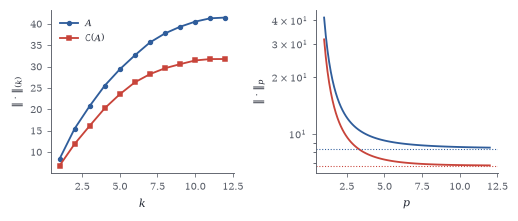

In [2]:
rng = np.random.default_rng(3); n = 12; A = rng.normal(size=(n, n)) + np.diag(np.linspace(3, -3, n))
CA = A.copy(); CA[:6, 6:] = 0; CA[6:, :6] = 0
sA, sC = np.linalg.svd(A, compute_uv=False), np.linalg.svd(CA, compute_uv=False)
fig, axs = plt.subplots(1, 2, figsize=(W, 1.9))
axs[0].plot(range(1, n + 1), np.cumsum(sA), "o-", color=BLUE, ms=2.5, label="$A$"); axs[0].plot(range(1, n + 1), np.cumsum(sC), "s-", color=RED, ms=2.5, label=r"$\mathcal{C}(A)$")
axs[0].set_xlabel("$k$"); axs[0].set_ylabel(r"$\|\cdot\|_{(k)}$"); axs[0].legend(fontsize=6)
ps = np.linspace(1, 12, 100); schat = lambda s, p: (s**p).sum()**(1 / p)
axs[1].plot(ps, [schat(sA, p) for p in ps], color=BLUE); axs[1].plot(ps, [schat(sC, p) for p in ps], color=RED)
axs[1].axhline(sA[0], color=BLUE, ls=":", lw=0.7); axs[1].axhline(sC[0], color=RED, ls=":", lw=0.7); axs[1].set_xlabel("$p$"); axs[1].set_ylabel(r"$\|\cdot\|_p$"); axs[1].set_yscale("log")

Unit balls of three unitarily invariant norms on real symmetric $2\times2$ matrices $\begin{bmatrix}a+c&b\\ b&a-c\end{bmatrix}$. The operator norm $|a|+r\le1$ gives a double cone; the trace norm $2\max(|a|,r)\le1$ gives a cylinder; Frobenius gives a sphere. The cone and the cylinder are polar (dual) to each other. The extreme points of the trace-norm ball are its two rim circles, which are exactly the rank-one matrices $\pm\frac12 vv^{\mathsf T}$, the reason why minimizing the trace norm promotes low rank.

findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


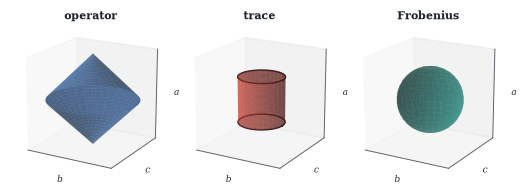

In [3]:
th = np.linspace(0, 2 * np.pi, 60); tt = np.linspace(0, 1, 20); TH, TT = np.meshgrid(th, tt)
fig = plt.figure(figsize=(W, 1.75))
def surf(ax, r, a, col):
    ax.plot_surface(r * np.cos(TH), r * np.sin(TH), a, color=col, alpha=0.55, lw=0, rstride=1, cstride=2)
for i, (ttl, col) in enumerate([("operator", BLUE), ("trace", RED), ("Frobenius", TEAL)]):
    ax = fig.add_subplot(1, 3, i + 1, projection="3d"); ax.view_init(elev=18, azim=-60)
    if i == 0:
        surf(ax, 1 - TT, TT, col); surf(ax, 1 - TT, -TT, col)
    elif i == 1:
        surf(ax, 0.5 + 0 * TT, TT - 0.5, col); surf(ax, 0.5 * TT, 0.5 + 0 * TT, col); surf(ax, 0.5 * TT, -0.5 + 0 * TT, col)
        ax.plot(0.5 * np.cos(th), 0.5 * np.sin(th), 0.5, color=INK, lw=1); ax.plot(0.5 * np.cos(th), 0.5 * np.sin(th), -0.5, color=INK, lw=1)
    else:
        ph = np.pi * TT; rr = np.sin(ph) / np.sqrt(2); surf(ax, rr, np.cos(ph) / np.sqrt(2), col)
    ax.set_xlim(-1, 1); ax.set_ylim(-1, 1); ax.set_zlim(-1, 1); ax.set_box_aspect((1, 1, 1)); ax.set_title(ttl, fontsize=7, pad=-2)
    ax.set_xlabel("$b$", fontsize=6, labelpad=-12); ax.set_ylabel("$c$", fontsize=6, labelpad=-12); ax.set_zlabel("$a$", fontsize=6, labelpad=-12)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])

Steepest descent directions for the same gradient $G$ in three norms, shown through their singular values. The gradient's singular values (grey) decay fast. Frobenius-normalized descent (blue) keeps the decay, trace-norm descent (red) uses only the top direction, operator-norm descent (gold) flattens the spectrum to all ones: every direction gets the same step. Right: the decrease of the linear model $\mathrm{tr}(G^{\mathsf T}D)$ per unit step is the dual norm, $\lVert G\rVert_F$, $\lVert G\rVert$ and $\lVert G\rVert_1$ respectively.

Text(0, 0.5, '$\\mathrm{tr}(G^{T}D)$')

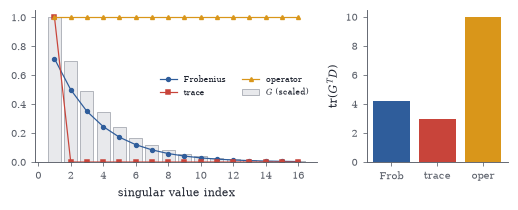

In [4]:
rng = np.random.default_rng(2); m = 16; Ug, _ = np.linalg.qr(rng.normal(size=(m, m))); Vg, _ = np.linalg.qr(rng.normal(size=(m, m)))
sg = 3.0 * 0.7 ** np.arange(m); Gm = Ug @ np.diag(sg) @ Vg.T
D_fro = Gm / np.linalg.norm(Gm); D_nuc = np.outer(Ug[:, 0], Vg[:, 0]); D_op = Ug @ Vg.T
fig, axs = plt.subplots(1, 2, figsize=(W, 1.8), gridspec_kw={"width_ratios": [2, 1]})
x = np.arange(1, m + 1); axs[0].bar(x, sg / sg.max(), color=LIGHT, edgecolor=GRAY, lw=0.4, label="$G$ (scaled)")
for D, c, lab, mk in [(D_fro, BLUE, "Frobenius", "o"), (D_nuc, RED, "trace", "s"), (D_op, GOLD, "operator", "^")]:
    axs[0].plot(x, np.linalg.svd(D, compute_uv=False), mk + "-", color=c, ms=2.5, lw=0.8, label=lab)
axs[0].set_xlabel("singular value index"); axs[0].legend(fontsize=5.5, ncol=2)
vals = [np.trace(Gm.T @ D) for D in (D_fro, D_nuc, D_op)]
axs[1].bar(["Frob", "trace", "oper"], vals, color=[BLUE, RED, GOLD]); axs[1].set_ylabel(r"$\mathrm{tr}(G^{T}D)$")

Matrix completion by singular value thresholding. A $60\times60$ matrix of rank $3$ is observed on $35\%$ of its entries. Left: the relative error of the iterates on all entries (blue) and on the observed ones (dashed) falls steadily. Right: singular values of the final iterate (red) match those of the true matrix (black squares) for the top three, while the rest are zero or nearly so.

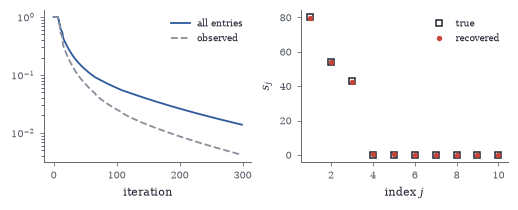

In [5]:
rng = np.random.default_rng(0); n, r = 60, 3; M = rng.normal(size=(n, r)) @ rng.normal(size=(r, n)); mask = rng.random((n, n)) < 0.35
Y = np.zeros((n, n)); tau = 5 * n; step = 1.2; errs, oerrs = [], []
for it in range(300):
    Uy, sy, Vy = np.linalg.svd(Y, full_matrices=False); X = (Uy * np.maximum(sy - tau, 0)) @ Vy
    Y += step * mask * (M - X); errs.append(np.linalg.norm(X - M) / np.linalg.norm(M)); oerrs.append(np.linalg.norm(mask * (X - M)) / np.linalg.norm(mask * M))
fig, axs = plt.subplots(1, 2, figsize=(W, 1.8))
axs[0].semilogy(errs, color=BLUE, label="all entries"); axs[0].semilogy(oerrs, "--", color=GRAY, label="observed"); axs[0].set_xlabel("iteration"); axs[0].legend(fontsize=6)
kk = np.arange(1, 11); axs[1].plot(kk, np.linalg.svd(M, compute_uv=False)[:10], "s", color=INK, ms=3.5, mfc="none", label="true"); axs[1].plot(kk, np.linalg.svd(X, compute_uv=False)[:10], "o", color=RED, ms=2.5, label="recovered")
axs[1].set_xlabel("index $j$"); axs[1].set_ylabel("$s_j$"); axs[1].legend(fontsize=6)

In [6]:
rng = np.random.default_rng(4); A5 = rng.normal(size=(5, 5)); U5, s5, Vt5 = np.linalg.svd(A5)
for name, B5, target in [("operator ball", U5 @ Vt5, s5.sum()), ("Frobenius ball", A5 / np.linalg.norm(A5), np.linalg.norm(A5)),
                         ("trace ball", np.outer(U5[:, 0], Vt5[0]), s5[0])]:
    print(f"{name:15s} max tr(B^T A) = {np.trace(B5.T @ A5):.6f}   dual norm = {target:.6f}")

operator ball   max tr(B^T A) = 10.558516   dual norm = 10.558516
Frobenius ball  max tr(B^T A) = 5.349363   dual norm = 5.349363
trace ball      max tr(B^T A) = 3.457138   dual norm = 3.457138


In [7]:
from scipy.linalg import polar
rng = np.random.default_rng(9); A4 = rng.normal(size=(4, 4)); Up, Pp = polar(A4)
base = [np.linalg.norm(A4 - Up, o) for o in (2, "fro", "nuc")]; worst = [np.inf] * 3
for _ in range(5000):
    V4, R4 = np.linalg.qr(rng.normal(size=(4, 4))); V4 *= np.sign(np.diag(R4))
    worst = [min(w, np.linalg.norm(A4 - V4, o)) for w, o in zip(worst, (2, "fro", "nuc"))]
for nm, b, w in zip(("operator", "Frobenius", "trace"), base, worst): print(f"{nm:9s} ||A-U|| = {b:.4f}   best random V: {w:.4f}")

operator  ||A-U|| = 2.4917   best random V: 2.5208
Frobenius ||A-U|| = 2.9993   best random V: 3.1860
trace     ||A-U|| = 4.9212   best random V: 5.1245
